# 274. H-Index
https://leetcode.com/problems/h-index/

## Complexity Comparison

| Approach | Time | Space | Description |
|----------|------|-------|-------------|
| Sort | O(n log n) | O(1) | Sort descending, find h |
| **Counting sort (Optimal)** | **O(n)** | **O(n)** | Count citations, cumulative sum |

## Methodology

Use counting sort since citations above n can be capped at n. Create a bucket array where `bucket[i]` = number of papers with exactly i citations (bucket[n] includes all >= n). Then iterate from n down to 0, accumulating the count. The first index where the cumulative count >= index is the h-index.

## Solutions

### C#

In [ ]:
public class Solution {
    public int HIndex(int[] citations) {
        int n = citations.Length;
        int[] bucket = new int[n + 1];
        foreach (int c in citations) {
            bucket[Math.Min(c, n)]++;
        }
        int total = 0;
        for (int i = n; i >= 0; i--) {
            total += bucket[i];
            if (total >= i) return i;
        }
        return 0;
    }
}

### Python

In [ ]:
class Solution:
    def hIndex(self, citations: list[int]) -> int:
        n = len(citations)
        bucket = [0] * (n + 1)
        for c in citations:
            bucket[min(c, n)] += 1
        total = 0
        for i in range(n, -1, -1):
            total += bucket[i]
            if total >= i:
                return i
        return 0

### Go

In [ ]:
func hIndex(citations []int) int {
    n := len(citations)
    bucket := make([]int, n+1)
    for _, c := range citations {
        bucket[min(c, n)]++
    }
    total := 0
    for i := n; i >= 0; i-- {
        total += bucket[i]
        if total >= i {
            return i
        }
    }
    return 0
}

### Rust

In [ ]:
impl Solution {
    pub fn h_index(citations: Vec<i32>) -> i32 {
        let n = citations.len();
        let mut bucket = vec![0; n + 1];
        for &c in &citations {
            bucket[c.min(n as i32) as usize] += 1;
        }
        let mut total = 0;
        for i in (0..=n).rev() {
            total += bucket[i];
            if total >= i as i32 {
                return i as i32;
            }
        }
        0
    }
}

## Example Scenarios

### 1. Common Case — Mixed Citations
**Input:** `citations = [3,0,6,1,5]`
Sorted descending: $[6,5,3,1,0]$. Walking the positions, $3$ papers have at least $3$ citations but not $4$, so the h-index is $3$.

### 2. Slightly Complex — Larger Values
**Input:** `citations = [10,8,5,4,3]`
Sorted descending the array is unchanged. At position $4$ the citation value is $4 \ge 4$, but position $5$ holds $3 < 5$, so $h = 4$.

### 3. Edge Case: Time Factor — Many Equal Papers
**Input:** $n = 10^4$ papers each cited exactly once
Counting-sort caps every citation at $n$ and tallies buckets in $O(n)$, beating the $O(n \log n)$ sort. Only $1$ paper threshold is met for $h=1$, so $h = 1$.

### 4. Edge Case: Space Factor — Single Uncited Paper
**Input:** `citations = [0]`
A lone paper with zero citations: no $h \ge 1$ can hold, so the h-index is $0$.

### 5. Almost-Impossible but Plausible — One Hugely Cited Paper
**Input:** `citations = [100]`
With only one paper, $h$ cannot exceed $n = 1$ no matter how large the count, so $h = 1$ (capping at $n$ matters).


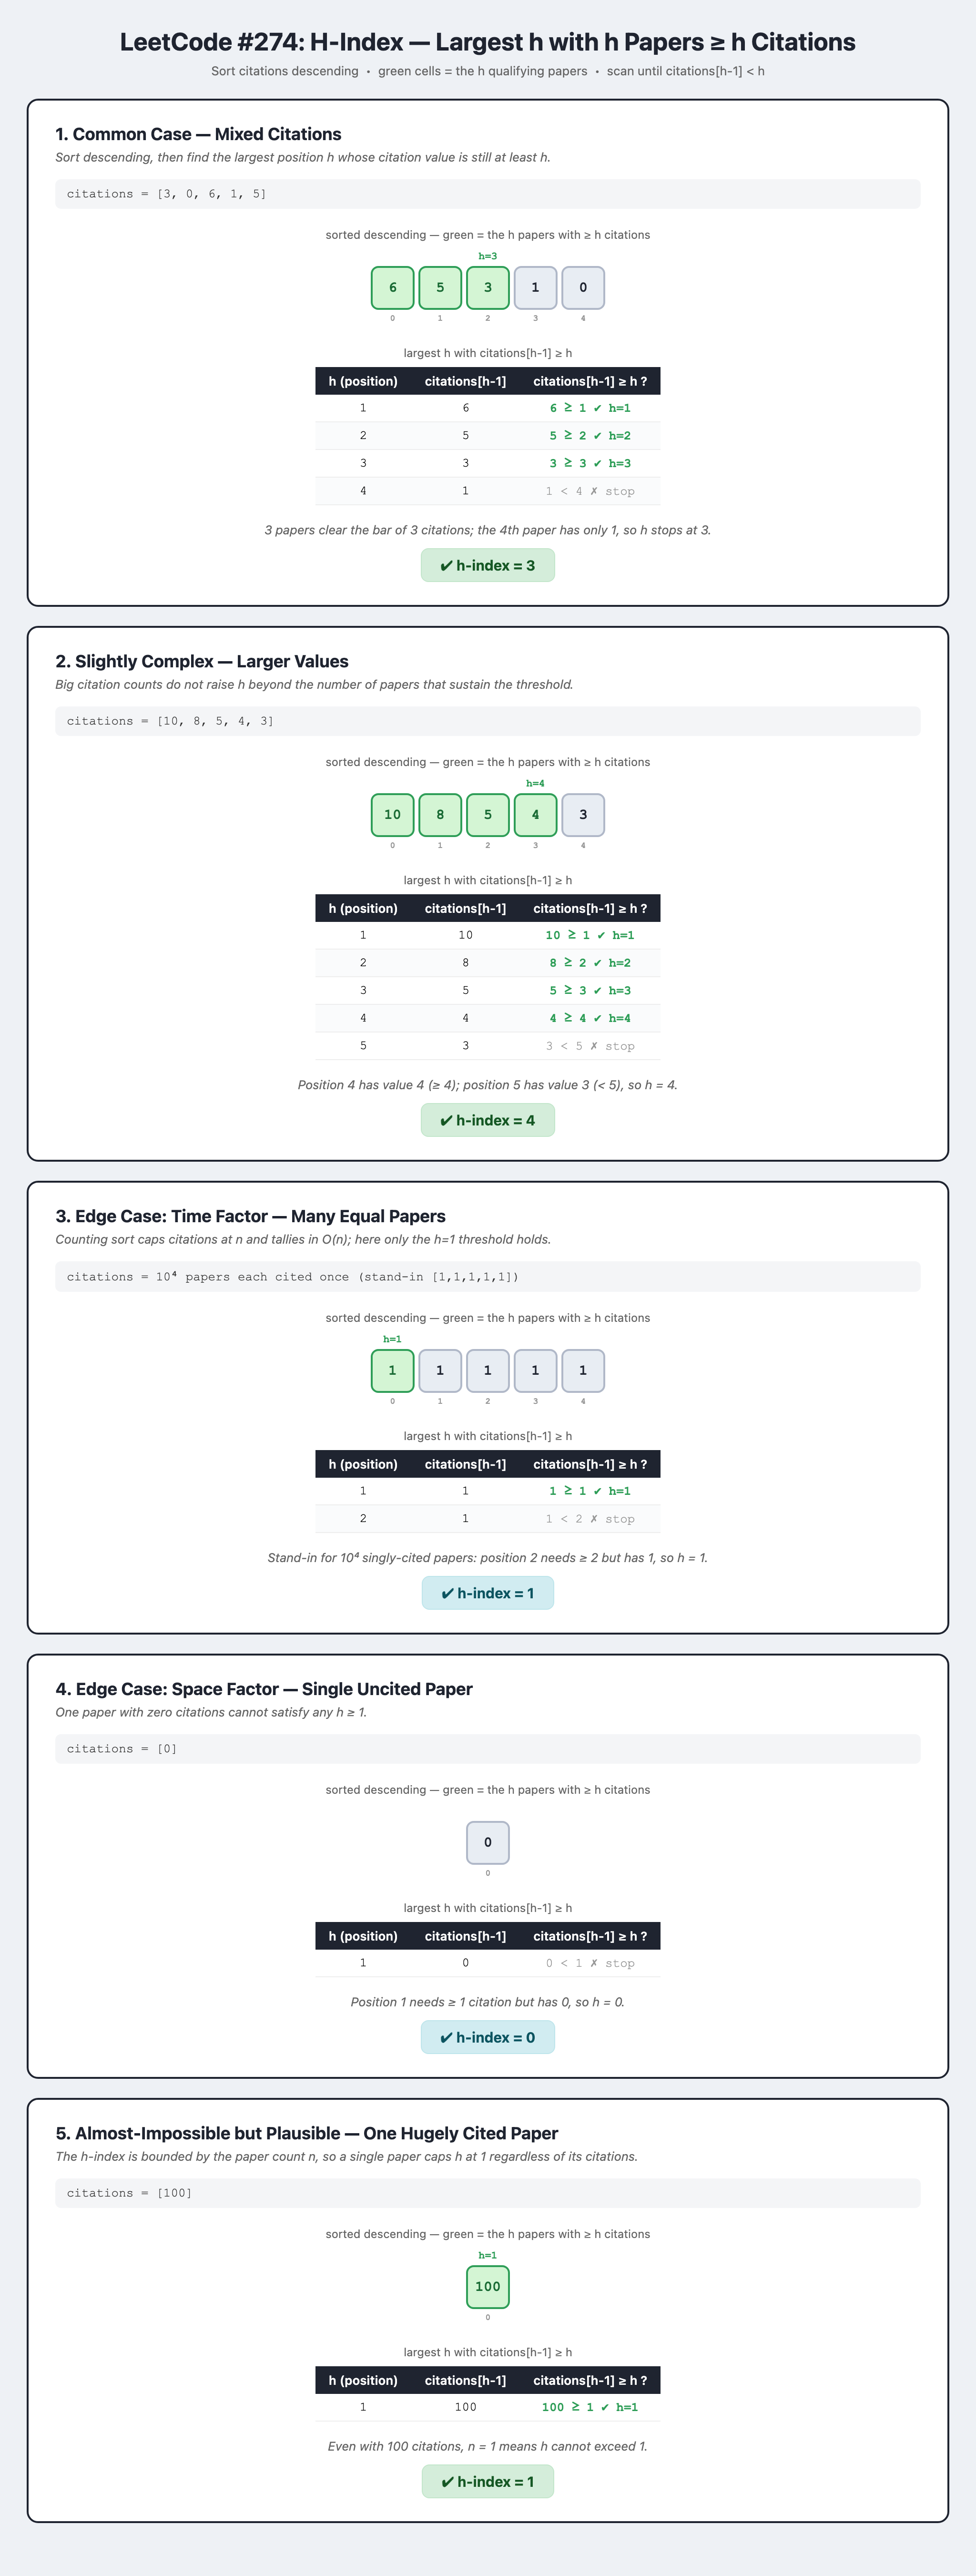